IRIS FLOWER CLASSIFICATION AND CLUSTERING PROJECT

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Dataset shape:
(150, 5)

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicate rows:
1

Flower species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Displaying Iris dataset pairplot...


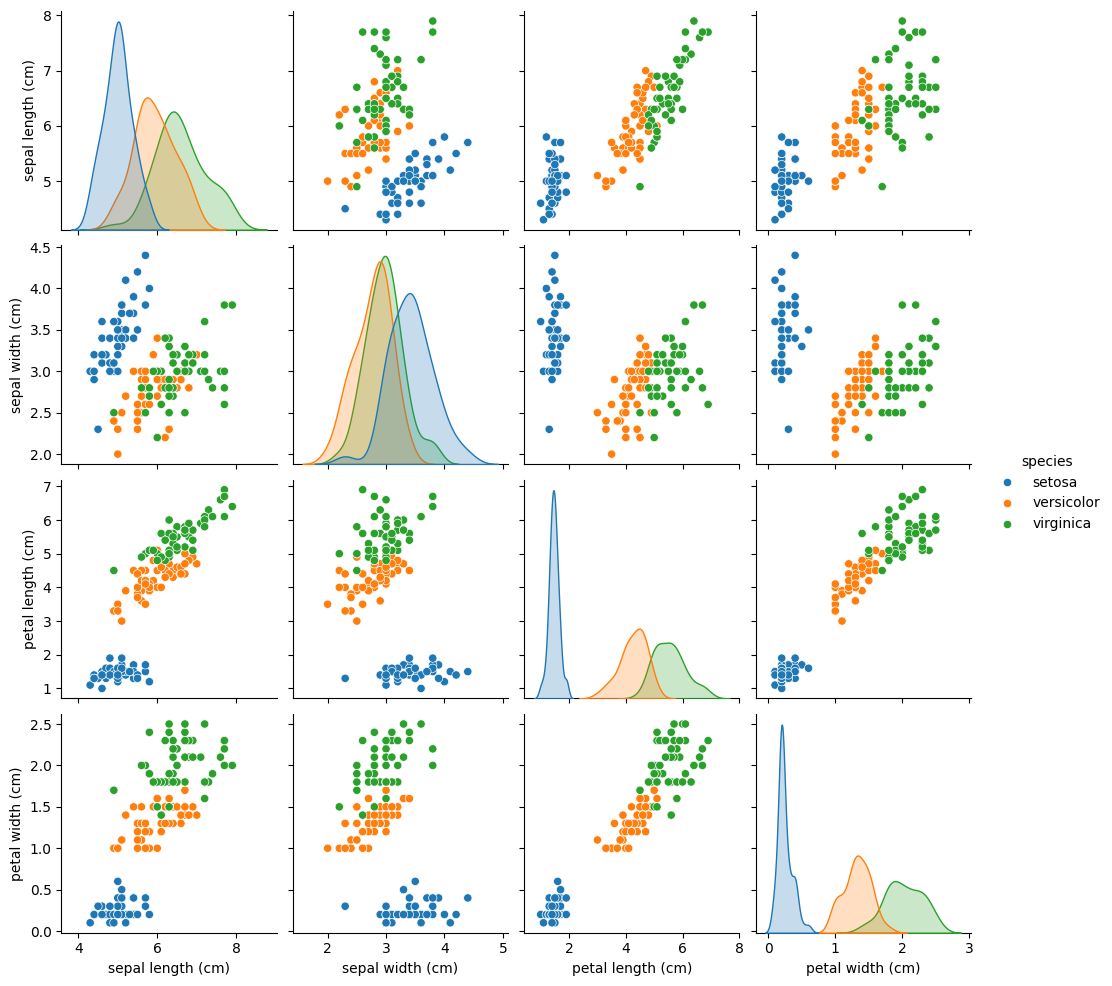


Dataset after removing duplicates: (149, 5)
Training samples: 119
Testing samples: 30

========== MODEL COMPARISON ==========
          Algorithm  Accuracy  Precision  Recall  F1 Score
Logistic Regression     0.933      0.933   0.933     0.933
                SVM     0.967      0.970   0.967     0.967
                KNN     0.933      0.944   0.933     0.933
           AdaBoost     0.933      0.933   0.933     0.933

Displaying classification performance graph...


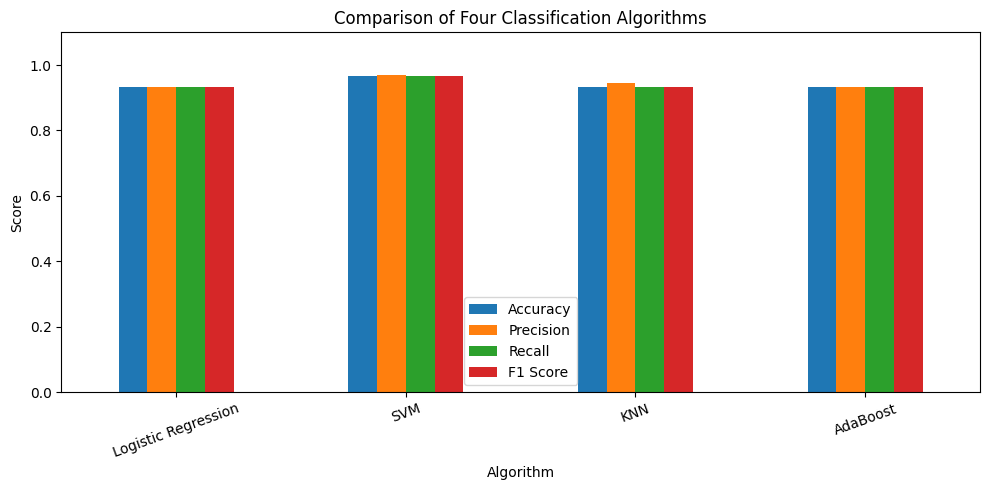


Best algorithm: SVM
Best model saved as best_iris_model.pkl

Predicted flower species: setosa


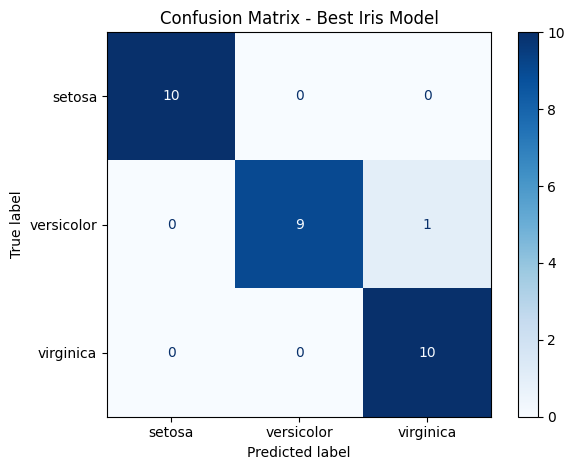


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

========== MAE: MEAN ABSOLUTE ERROR ==========
Logistic Regression: MAE = 0.0667
SVM: MAE = 0.0333
KNN: MAE = 0.0667
AdaBoost: MAE = 0.0667

Displaying MAE graph...


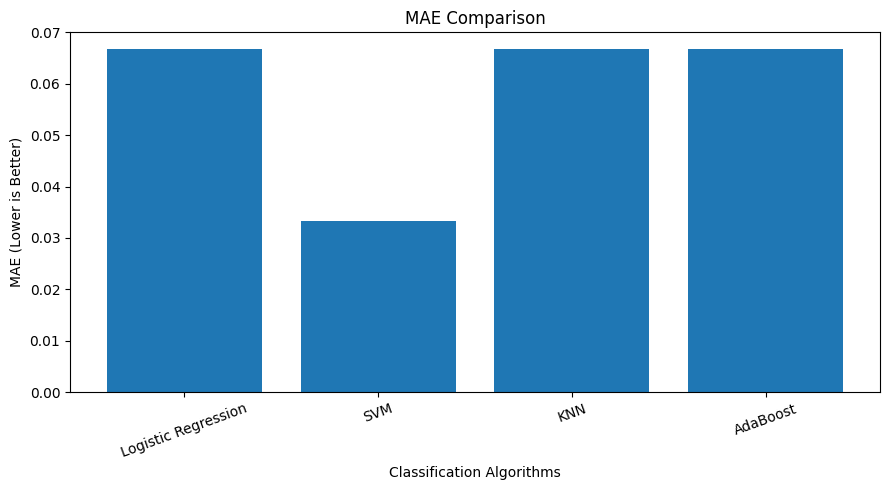


========== MSE: MEAN SQUARED ERROR ==========
Logistic Regression: MSE = 0.0667
SVM: MSE = 0.0333
KNN: MSE = 0.0667
AdaBoost: MSE = 0.0667

Displaying MSE graph...


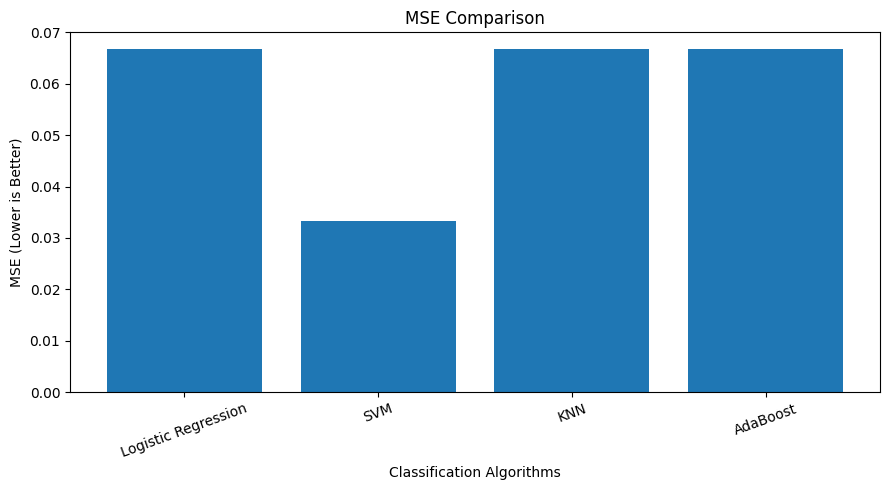


========== RMSE: ROOT MEAN SQUARED ERROR ==========
Logistic Regression: RMSE = 0.2582
SVM: RMSE = 0.1826
KNN: RMSE = 0.2582
AdaBoost: RMSE = 0.2582

Displaying RMSE graph...


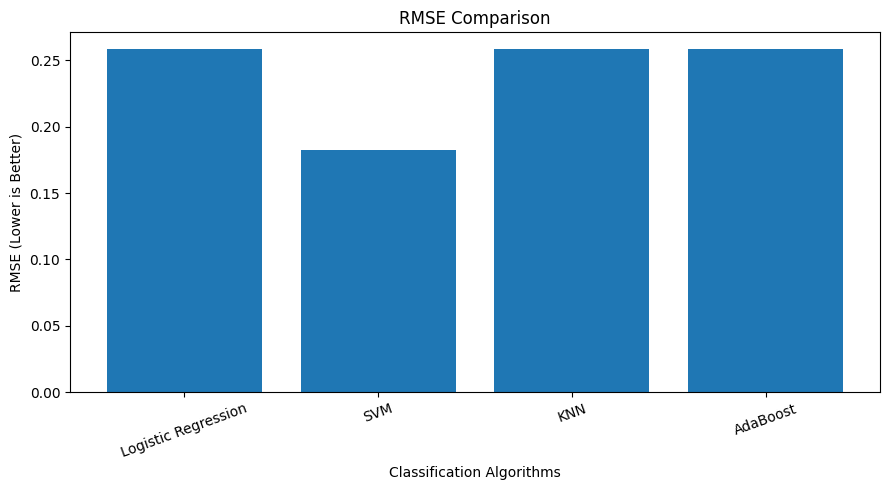


========== K-MEANS CLUSTERING ==========

First five clustered samples:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Cluster  
0        1  
1        1  
2        1  
3        1  
4        1  

Samples in each cluster:
Cluster
0    52
1    50
2    47
Name: count, dtype: int64

Silhouette Score: 0.4607

Displaying K-Means clustering graph...


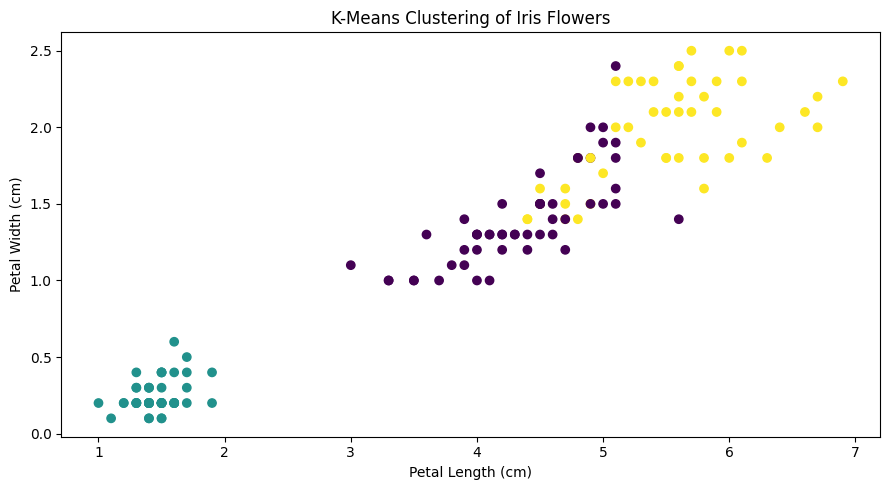


PROJECT COMPLETED SUCCESSFULLY!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import AdaBoostClassifier

from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    mean_squared_error,
    silhouette_score
)


# STEP 1: LOAD IRIS DATASET

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = [
    iris.target_names[i] for i in iris.target
]

print("IRIS FLOWER CLASSIFICATION AND CLUSTERING PROJECT")

print("\nFirst five rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)


# STEP 2: CHECK MISSING VALUES

print("\nMissing values:")
print(df.isnull().sum())


# STEP 3: CHECK DUPLICATES

print("\nDuplicate rows:")
print(df.duplicated().sum())


# STEP 4: CLASS DISTRIBUTION

print("\nFlower species distribution:")
print(df["species"].value_counts())


# STEP 5: PAIRPLOT

print("\nDisplaying Iris dataset pairplot...")

sns.pairplot(df, hue="species")
plt.show()


# STEP 6: PREPARE DATA

df = df.drop_duplicates()

X = df.drop("species", axis=1)
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nDataset after removing duplicates:", df.shape)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# STEP 7: FOUR CLASSIFICATION ALGORITHMS

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=50,
        random_state=42
    )
}


# STEP 8: TRAIN AND EVALUATE MODELS

results = []
trained_models = {}
all_predictions = {}

for name, algorithm in models.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", algorithm)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    trained_models[name] = pipeline
    all_predictions[name] = predictions

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("\n========== MODEL COMPARISON ==========")
print(results_df.round(3).to_string(index=False))


# STEP 9: CLASSIFICATION PERFORMANCE GRAPH

print("\nDisplaying classification performance graph...")

results_df.set_index("Algorithm")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Comparison of Four Classification Algorithms")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# STEP 10: SAVE BEST MODEL

best_name = results_df.loc[
    results_df["F1 Score"].idxmax(),
    "Algorithm"
]

best_model = trained_models[best_name]

joblib.dump(best_model, "best_iris_model.pkl")

print("\nBest algorithm:", best_name)
print("Best model saved as best_iris_model.pkl")


# STEP 11: PREDICT NEW FLOWER

new_flower = pd.DataFrame([{
    "sepal length (cm)": 5.1,
    "sepal width (cm)": 3.5,
    "petal length (cm)": 1.4,
    "petal width (cm)": 0.2
}])

prediction = best_model.predict(new_flower)

print("\nPredicted flower species:", prediction[0])


# STEP 12: CONFUSION MATRIX

y_pred = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=best_model.classes_
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - Best Iris Model")
plt.tight_layout()
plt.show()

print("\nConfusion Matrix:")
print(cm)


# STEP 13: CALCULATE MAE, MSE AND RMSE

# Map species names to numeric labels consistently
label_numbers = {
    species: number
    for number, species in enumerate(iris.target_names)
}

y_test_numeric = y_test.map(label_numbers).to_numpy()

mae_values = []
mse_values = []
rmse_values = []

for name, predictions in all_predictions.items():

    predictions_numeric = pd.Series(
        predictions
    ).map(label_numbers).to_numpy()

    mae_values.append(
        mean_absolute_error(
            y_test_numeric,
            predictions_numeric
        )
    )

    mse_values.append(
        mean_squared_error(
            y_test_numeric,
            predictions_numeric
        )
    )

    rmse_values.append(
        np.sqrt(
            mean_squared_error(
                y_test_numeric,
                predictions_numeric
            )
        )
    )


# STEP 14: MAE OUTPUT AND GRAPH

print("\n========== MAE: MEAN ABSOLUTE ERROR ==========")

for name, value in zip(models.keys(), mae_values):
    print(f"{name}: MAE = {value:.4f}")

print("\nDisplaying MAE graph...")

plt.figure(figsize=(9, 5))
plt.bar(models.keys(), mae_values)
plt.title("MAE Comparison")
plt.xlabel("Classification Algorithms")
plt.ylabel("MAE (Lower is Better)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# STEP 15: MSE OUTPUT AND GRAPH

print("\n========== MSE: MEAN SQUARED ERROR ==========")

for name, value in zip(models.keys(), mse_values):
    print(f"{name}: MSE = {value:.4f}")

print("\nDisplaying MSE graph...")

plt.figure(figsize=(9, 5))
plt.bar(models.keys(), mse_values)
plt.title("MSE Comparison")
plt.xlabel("Classification Algorithms")
plt.ylabel("MSE (Lower is Better)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# STEP 16: RMSE OUTPUT AND GRAPH

print("\n========== RMSE: ROOT MEAN SQUARED ERROR ==========")

for name, value in zip(models.keys(), rmse_values):
    print(f"{name}: RMSE = {value:.4f}")

print("\nDisplaying RMSE graph...")

plt.figure(figsize=(9, 5))
plt.bar(models.keys(), rmse_values)
plt.title("RMSE Comparison")
plt.xlabel("Classification Algorithms")
plt.ylabel("RMSE (Lower is Better)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# STEP 17: K-MEANS CLUSTERING

print("\n========== K-MEANS CLUSTERING ==========")

# Scale features for clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create three clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

cluster_df = X.copy()
cluster_df["Cluster"] = clusters

print("\nFirst five clustered samples:")
print(cluster_df.head())

print("\nSamples in each cluster:")
print(cluster_df["Cluster"].value_counts().sort_index())

silhouette = silhouette_score(X_scaled, clusters)

print(f"\nSilhouette Score: {silhouette:.4f}")


# K-MEANS CLUSTERING GRAPH

print("\nDisplaying K-Means clustering graph...")

plt.figure(figsize=(9, 5))

plt.scatter(
    X.iloc[:, 2],
    X.iloc[:, 3],
    c=clusters
)

plt.title("K-Means Clustering of Iris Flowers")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.tight_layout()
plt.show()


print("\nPROJECT COMPLETED SUCCESSFULLY!")